In [29]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics.cluster import contingency_matrix 
from sklearn.metrics import adjusted_rand_score
import matplotlib.pyplot as plt
import pandas as pd

In [30]:
#pd.set_option('display.max_rows', 200)
%matplotlib widget
SMALL_SIZE = 9
MEDIUM_SIZE = 9
BIGGER_SIZE = 14
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=MEDIUM_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title
plt.rc('figure', autolayout=True)

In [38]:
import glob
path = "T:/BMS/new_Databackup/Jan/fiscas-validator/palma/pixel_size/deleted_pixels/reports"
result_files = glob.glob(path + "/results_summary_*.csv")
df = pd.read_csv(result_files[0])

In [39]:
for file in result_files[1:]:
    df = pd.concat([df, pd.read_csv(file)], ignore_index=True)
df

,ID,cell_types,output,use_perfect_registration,use_perfect_segmentation,teaching_imprecision,canvas_size,mic_spacing,ms_spacing,cell_density,...,m/z 0,STD m/z 0,m/z 1,STD m/z 1,m/z 2,STD m/z 2,m/z 3,STD m/z 3,FPR,ARI
0,901f91cf-6dfc-4a72-9ab8-b3817a76c390,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5.0,0.2,...,0.081980,0.078712,0.081996,0.078668,0.081574,0.078906,0.083184,0.083169,0.0,0.794080
1,e6fc9aee-048e-415c-b439-f6ca7000665d,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5.0,0.2,...,0.070662,0.060905,0.070607,0.060955,0.070194,0.060805,0.070411,0.061790,0.0,0.579498
2,f94b4353-8b0b-4d76-921f-f31672a87344,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.750000,7.5,0.2,...,0.171870,0.190839,0.172104,0.190862,0.171830,0.191159,0.170327,0.191259,0.0,0.709927
3,ce197123-25d3-45a3-8393-607e9718855c,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,10.0,0.2,...,0.288995,0.297304,0.289069,0.297457,0.289136,0.297414,0.285640,0.298803,0.0,0.734514
4,f8ee0c3d-d100-4fef-9cc5-c3d5dd7ce831,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,15.0,0.2,...,0.616847,0.345915,0.616862,0.345909,0.616851,0.345905,0.616841,0.345890,0.0,0.877703
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
81,4d7e19f5-7b3f-4148-aaff-68e51e5c924a,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.700000,17.5,0.2,...,0.627332,0.354409,0.627197,0.354428,0.627375,0.354287,0.625928,0.355504,0.0,0.947036
82,272ebe1a-09c2-4d4e-95df-5aca07b54444,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,20.0,0.2,...,0.624012,0.390693,0.624104,0.389931,0.624151,0.390141,0.618808,0.410242,0.0,0.767529
83,7bf78353-4d21-4ab2-8cf0-185ea5148173,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5.0,0.2,...,0.061057,0.060995,0.061068,0.061002,0.060968,0.060935,0.061042,0.061159,0.0,0.760281
84,97502384-9465-49c6-b4dd-e324199683f5,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,1.000000,1.0,0.2,...,0.005794,0.007291,0.005788,0.007423,0.006077,0.007541,0.019244,0.112015,0.0,0.481043


In [40]:
df['remove_ambiguous']

0     True
1     True
2     True
3     True
4     True
      ... 
81    True
82    True
83    True
84    True
85    True
Name: remove_ambiguous, Length: 86, dtype: bool

In [41]:
mean_spacing = df.groupby('ms_spacing')[['ms_spacing', 'm/z 0', 'm/z 1', 'm/z 2', 'm/z 3', 'FPR', 'ARI']].mean()
std_spacing = df.groupby('ms_spacing')[['ms_spacing', 'm/z 0', 'm/z 1', 'm/z 2', 'm/z 3', 'FPR', 'ARI']].std()

<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not w

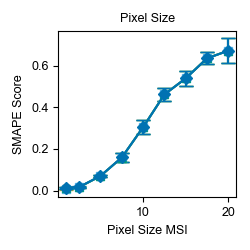

In [42]:
colors = ['#E69F00', '#56B4E9', '#009E73', '#0072B2']
markers = ['o', 's', '^', 'D']
labels = ['$\mathit{m/z}$ 1', '$\mathit{m/z}$ 2', '$\mathit{m/z}$ 3', '$\mathit{m/z}$ 4']
plt.figure(figsize=(2.5,2.5))
for i, mz in enumerate(['m/z 0', 'm/z 1', 'm/z 2', 'm/z 3']):
    plt.errorbar(mean_spacing['ms_spacing'], mean_spacing[mz], yerr=std_spacing[mz], label=labels[i], color=colors[i], marker=markers[i], fmt='o-', capsize=5)
plt.xlabel('Pixel Size MSI')
plt.ylabel('SMAPE Score')
plt.title('Pixel Size')
#plt.legend()
plt.tight_layout()
plt.savefig(path + "/evaluation/ms_spacing_results.png", dpi=600)
plt.show()

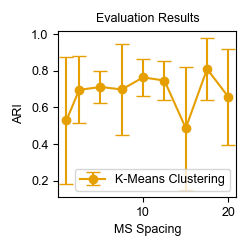

In [43]:
plt.figure(figsize=(2.5,2.5))
plt.errorbar(mean_spacing['ms_spacing'], mean_spacing['ARI'], yerr=std_spacing['ARI'], label='K-Means Clustering', color=colors[0], fmt='o-', capsize=5)
plt.xlabel('MS Spacing')
plt.ylabel('ARI')
plt.title('Evaluation Results')
plt.legend()
plt.tight_layout()
plt.savefig(path + "/evaluation/ms_spacing_ARI_results.png", dpi=600)
plt.show()

In [28]:
morphometry_df = pd.read_csv("./Cell_images/v3/output_v3/Segmentation_5.csv", sep=",")
morphometry_df

,ImageNumber,ObjectNumber,AreaShape_Area,AreaShape_BoundingBoxArea,AreaShape_BoundingBoxMaximum_X,AreaShape_BoundingBoxMaximum_Y,AreaShape_BoundingBoxMinimum_X,AreaShape_BoundingBoxMinimum_Y,AreaShape_Center_X,AreaShape_Center_Y,...,Neighbors_FirstClosestObjectNumber_Adjacent,Neighbors_NumberOfNeighbors_100,Neighbors_NumberOfNeighbors_Adjacent,Neighbors_PercentTouching_100,Neighbors_PercentTouching_Adjacent,Neighbors_SecondClosestDistance_100,Neighbors_SecondClosestDistance_Adjacent,Neighbors_SecondClosestObjectNumber_100,Neighbors_SecondClosestObjectNumber_Adjacent,Number_Object_Number
0,5,1,6887,11284,1740,126,1649,2,1702.477566,67.284594,...,29,4.0,2.0,100.000000,28.604651,81.841231,81.841231,41,41,1
1,5,2,4910,9120,12393,82,12279,2,12338.714664,37.881670,...,10,4.0,1.0,100.000000,10.098522,119.085219,119.085219,42,42,2
2,5,3,10870,16335,10113,127,9978,6,10053.154922,69.705980,...,38,0.0,0.0,0.000000,0.000000,382.723849,382.723849,189,189,3
3,5,4,5352,7392,1834,105,1757,9,1798.579970,56.422085,...,29,3.0,1.0,100.000000,17.919075,96.714353,96.714353,1,1,4
4,5,5,1681,3552,4373,111,4336,15,4356.444973,63.594289,...,7,1.0,0.0,95.864662,0.000000,226.561741,226.561741,108,108,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2878,5,2879,3093,5670,2210,10260,2129,10190,2169.531199,10223.916263,...,2842,0.0,0.0,0.000000,0.000000,304.386764,304.386764,2858,2858,2879
2879,5,2880,1035,1504,8536,10222,8489,10190,8511.571981,10205.326570,...,2868,1.0,0.0,100.000000,0.000000,631.059752,631.059752,2822,2822,2880
2880,5,2881,380,572,2995,10217,2973,10191,2982.844737,10203.678947,...,2876,1.0,1.0,100.000000,31.111111,243.336614,243.336614,2872,2872,2881
2881,5,2882,5666,9125,12659,10295,12534,10222,12599.131310,10258.482880,...,2870,0.0,0.0,0.000000,0.000000,260.611158,260.611158,2864,2864,2882


In [26]:
exp = pd.read_csv("./Cell_images/v3/output_v3/Image.csv", sep=",")
exp[['URL_FITC']].values

array([['file:///D:/PROJECTS/Dreisewerd/Jan/cell_images_v3/063_C4_Colo205_10x_FITC.tif'],
       ['file:///D:/PROJECTS/Dreisewerd/Jan/cell_images_v3/064_C5_ACHN_10x_FITC.tif'],
       ['file:///D:/PROJECTS/Dreisewerd/Jan/cell_images_v3/064_C8_ACHN_10x_FITC.tif'],
       ['file:///D:/PROJECTS/Dreisewerd/Jan/cell_images_v3/065_C8_DLD1_10x_FITC.tif'],
       ['file:///D:/PROJECTS/Dreisewerd/Jan/cell_images_v3/20230824_C1_A498_10x_FITC.tif']],
      dtype=object)